Configuraciones de helicopteros:
1. Rotor principal y de cola, simple pero peligroso para el personal en tierra. Un ejemplo es el diseño de fan-tail como el AS 365 N2 Dauphin 2.
2. Rotor Jet, plantea una solución al balance de torque pero en consecuencia tenemos una dinámica más compleja de las palas. Un ejemplo es el Fairey Rotodyne.
3. Rotor coaxial, palas contrarotatorias para el balance de torque pero el control y el hub del rotor es más complejo. Ejemplos son los Kamov Ka-32a y Ka-266.
4. Rotor en cada pala, se necesita una menor potencia en vuelo horizontal pero como consecuencia se obtiene más resistencia parasitaria y peso estructural. Un ejemplo es el V22 Osprey.
5. En tandem, fuselaje limpio y un CG distribuido, complejidad en transmision de potencia. Un ejemplo es el CH-47.

In [16]:

import numpy as np
"""
Analisis y performance de vuelo de helicoptero
para Darpa Lift Challenge -2 del 2028
Se hace un analisis de optimización con ecuaciones de performance básicas
"""

# Funciones de conversion de unidades
def lb2kg (valor):
    valor=valor*0.454
    return valor
def kg2N (valor):
    valor=valor*9.81
    return valor
def N2kgf (valor):
    valor=valor/9.81
    return valor

# Considerando un ratio de peso a payload de 1:4 para una aeronave de 55 lb (por reglamento)
# El ratio de payload puede ser incrementado, el del año 2026 fue de 1:4
PayloadRatio = 4
MasaAeronave = 55 # lbs
MasaTotal = MasaAeronave*PayloadRatio+MasaAeronave
print(f"La masa total es: {MasaTotal} lbs")
MasaAeronaveKg = lb2kg(MasaAeronave)
Payload = PayloadRatio*MasaAeronaveKg
print(f"El payload es: {Payload} kg")
EmpujeRequeridoKgf= Payload + MasaAeronaveKg
EmpujeRequerido= Payload + MasaAeronaveKg
EmpujeRequerido= kg2N(EmpujeRequerido) # Empuje mínimo para mantenerse flotando
print(f"El valor de sustentación necesario para mantener el vuelo es: {EmpujeRequerido} N {EmpujeRequeridoKgf} Kgf")

# Se requiere de 1225 N mínimo para mantener una aeronave de 55 lbs con un payload de aprox 100kg
# Estos valores pueden variar dependiendo del payload ratio

La masa total es: 275 lbs
El payload es: 99.88000000000001 kg
El valor de sustentación necesario para mantener el vuelo es: 1224.7785000000001 N 124.85000000000001 Kgf


124.85000000000001
Base: T = 1663 N (169.5 kgf), P = 31.56 kW, T/P = 5.37 kgf/kW

+10% en       dT %    dP %  d(T/P) %
V_tip         21.0    33.1      -9.1
D             21.0    21.0       0.0
sigma         10.0    14.8      -4.2
C_Tsigma      10.0    13.7      -3.2
rho           10.0    10.0       0.0
kappa          0.0     8.9      -8.2
Cd0            0.0     1.1      -1.1


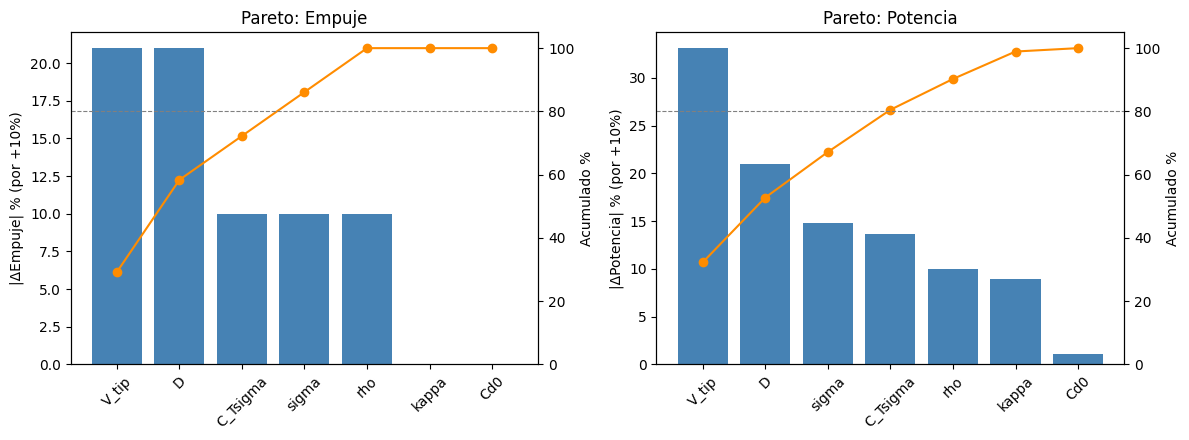

Empuje meta: 1224.7785000000001
D requerido = 1.717 m -> T = 124.8 kgf, P = 23.25 kW


In [ ]:
import numpy as np
# Tomemos los valores mínimos para flotar en kgf y Nws
# Podemos asumir una velocidad horizontal mínima de 15 m/s o más
# Los volumenes de la aeronave se pueden ignorar de momento
EmpujeRequerido
EmpujeRequeridoKgf
print(EmpujeRequeridoKgf)

# Ahora analizaremos los parametros requeridos para conseguir estos valores
# Empezaremos por las variables que construyen la ecuación de empuje para una aeronave que funciona con rotores
# De acuerdo con lo visto en el 2do capitulo del libro Fundamentals of Helicopter Aerodynamics haremos un analisis de sensibilidad (Pareto)
# para el empuje generado y potencia requerida 
parametros_rotor = dict(
    C_Tsigma= 0.12,     # Product de coef. de empuje y solides  
    sigma= 0.09,        # Solides del rotor, fracción del rotor cubierta por un alabe sigma= (N*c)/pi*R
                        # N: num. de palas, c: cuerda, R: radio de rotor 
    V_tip= 200,         # Velocidad en punta de pala
    rho= 1.225,         # Densidad del aire
    D=2,                # Diametro de rotor 
    kappa=1.15,         # Correción de factor de potencia inducida, supone flujo uniforme pero se generan perdidas por vortices en punta
                        # y el flujo no es uniforme al entrar al rotor k= 1 idea 1.1-1.2 real
    Cd0=0.01            # Resistencia al avance del pefil 
    )

def rotor(C_Tsigma, sigma, V_tip, rho, D, kappa, Cd0):
    A, C_T = np.pi*D**2/4, C_Tsigma*sigma       # Es "asignación variable" las variables de la izquierda se les asigna el valor de la derecha
    T = C_T*rho*A*V_tip**2
    P = (kappa*C_T**1.5/np.sqrt(2) + sigma*Cd0*0.125)*rho*A*V_tip**3
    return T, P

T0, P0 = rotor(**parametros_rotor)
print(f"Base: T = {T0:.0f} N ({T0/9.81:.1f} kgf), P = {P0/1e3:.2f} kW, T/P = {T0/9.81/(P0/1e3):.2f} kgf/kW\n")

filas = []
for k in parametros_rotor:
    T, P = rotor(**{**parametros_rotor, k: parametros_rotor[k] * 1.10})
    dT, dP = (T/T0 - 1) * 100, (P/P0 - 1) * 100
    dTP = ((T/P) / (T0/P0) - 1) * 100
    filas.append((k, dT, dP, dTP))
 
print(f"{'+10% en':<10}{'dT %':>8}{'dP %':>8}{'d(T/P) %':>10}")
for k, dT, dP, dTP in sorted(filas, key=lambda f: abs(f[1]) + abs(f[2]), reverse=True):
    print(f"{k:<10}{dT:>8.1f}{dP:>8.1f}{dTP:>10.1f}")

# Grafico de pareto 
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, col, titulo in zip(axes, [1, 2], ["Empuje", "Potencia"]):
    datos   = sorted(filas, key=lambda f: abs(f[col]), reverse=True)  # mayor a menor
    nombres = [f[0] for f in datos]
    valores = np.array([abs(f[col]) for f in datos])
    acum    = np.cumsum(valores) / valores.sum() * 100                # % acumulado

    ax.bar(nombres, valores, color="steelblue")
    ax.set_ylabel(f"|Δ{titulo}| % (por +10%)")
    ax.set_title(f"Pareto: {titulo}")
    ax.tick_params(axis="x", rotation=45)

    ax2 = ax.twinx()                                   # segundo eje para la curva
    ax2.plot(nombres, acum, "o-", color="darkorange")
    ax2.axhline(80, ls="--", color="gray", lw=0.8)     # línea del 80%
    ax2.set_ylim(0, 105)
    ax2.set_ylabel("Acumulado %")

plt.tight_layout()
plt.show()

# Goal seek para conseguir el empuje requerido en base al peso acordado
def goal_seek(f, objetivo, x_min, x_max, tol=1e-6, max_iter=100):
    """Busca x en [x_min, x_max] tal que f(x) = objetivo (bisección)."""
    for _ in range(max_iter):
        x_mid = (x_min + x_max) / 2
        # ¿El cruce con el objetivo está en la mitad izquierda?
        if (f(x_min) - objetivo) * (f(x_mid) - objetivo) <= 0:
            x_max = x_mid
        else:
            x_min = x_mid
        if x_max - x_min < tol:
            break
    return (x_min + x_max) / 2

# Valor meta en kgf
T_meta = EmpujeRequeridoKgf * 9.81
print(f"Empuje meta: {T_meta}")
D_req = goal_seek(lambda D: rotor(**{**parametros_rotor, "D": D})[0], T_meta, 0.5, 10)
T, P  = rotor(**{**parametros_rotor, "D": D_req})

print(f"D requerido = {D_req:.3f} m -> T = {T/9.81:.1f} kgf, P = {P/1e3:.2f} kW")

